# 🏠 House Price Prediction Using Regression

---

## Project Objective

In this project we build a **machine-learning model that predicts house prices** based on various property features such as area, number of bedrooms, age of the house, location score, and more.

We will:
- **Generate** a realistic synthetic dataset
- **Explore** the data with visualisations
- **Pre-process** features for modelling
- **Train and compare** five regression algorithms
- **Evaluate** each model with standard metrics
- **Save** the best model for future use

> **Audience:** Beginners who are learning Python, Pandas, data visualisation, and scikit-learn regression.

---
## Section 2 — Import Libraries

We start by importing every library we will need throughout the notebook.

| Library | Purpose |
|---|---|
| `numpy` | Numerical operations |
| `pandas` | Data manipulation |
| `matplotlib` | Base plotting |
| `seaborn` | Statistical visualisations |
| `scikit-learn` | Machine-learning models & preprocessing |
| `joblib` | Model persistence |

In [1]:
# ── Standard library ──────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Numerical & data ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Scikit-learn: preprocessing ───────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ── Scikit-learn: models ──────────────────────────────────────────────────────
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ── Scikit-learn: metrics ─────────────────────────────────────────────────────
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Model persistence ─────────────────────────────────────────────────────────
import joblib

# ── Global plot style ─────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

print('All libraries imported successfully!')

All libraries imported successfully!


---
## Section 3 — Generate the Dataset

We programmatically create a **synthetic** house-price dataset.

The **target price** is derived from a realistic linear formula:

```
price = 120 x area + 8000 x bedrooms + 6000 x bathrooms
      - 1200 x age - 3500 x distance + 20000 x garage
      + 15000 x garden + 2000 x floor + 12000 x location_score
      + 50000 (base) + noise
```

A fixed random seed (`42`) ensures the dataset is **reproducible**.

In [ ]:
# ── Reproducible RNG ──────────────────────────────────────────────────────────
SEED = 42
rng  = np.random.default_rng(SEED)
N    = 1000   # number of samples

# ── Feature generation ────────────────────────────────────────────────────────
area_sqft        = rng.integers(500,  4001, N).astype(float)
bedrooms         = rng.integers(1,    6,    N).astype(float)
bathrooms        = rng.integers(1,    4,    N).astype(float)
age_years        = rng.integers(0,    51,   N).astype(float)
distance_to_city = np.round(rng.uniform(1, 50, N), 2)
garage           = rng.integers(0, 2, N).astype(float)
garden           = rng.integers(0, 2, N).astype(float)
floor            = rng.integers(0, 16, N).astype(float)
location_score   = np.round(rng.uniform(1, 10, N), 2)

# ── Price formula with Gaussian noise ────────────────────────────────────────
noise = rng.normal(0, 15_000, N)

house_price = (
      120  * area_sqft
    + 8_000  * bedrooms
    + 6_000  * bathrooms
    - 1_200  * age_years
    - 3_500  * distance_to_city
    + 20_000 * garage
    + 15_000 * garden
    + 2_000  * floor
    + 12_000 * location_score
    + 50_000
    + noise
)

# Keep prices in a realistic range: ₹50k to ₹1M
house_price = np.clip(house_price, 50_000, 1_000_000).round(2)

# ── Assemble DataFrame ────────────────────────────────────────────────────────
df = pd.DataFrame({
    'area_sqft':           area_sqft,
    'bedrooms':            bedrooms,
    'bathrooms':           bathrooms,
    'age_years':           age_years,
    'distance_to_city_km': distance_to_city,
    'garage':              garage,
    'garden':              garden,
    'floor':               floor,
    'location_score':      location_score,
    'house_price':         house_price,
})

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

# ── Save dataset ──────────────────────────────────────────────────────────────
df.to_csv('house_price_dataset.csv', index=False)
print(f'Dataset saved as house_price_dataset.csv')
print(f'Rows: {df.shape[0]}  |  Columns: {df.shape[1]}')
print(f'Missing values : {df.isnull().sum().sum()}')
print(f'Duplicate rows : {df.duplicated().sum()}')

print('\nFirst 10 rows:')
df.head(10)

In [ ]:
# Basic statistics
print('Basic Statistics:')
df.describe().style.format('{:,.2f}')

---
## Section 4 — Load the Dataset

We reload the CSV from disk — this is how you would typically start if the dataset were pre-existing.

In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────
df = pd.read_csv('house_price_dataset.csv')

print('=' * 50)
print('  DATASET OVERVIEW')
print('=' * 50)
print(f'  Shape          : {df.shape[0]} rows x {df.shape[1]} columns')
print(f'  Columns        : {list(df.columns)}')
print()
print('First 10 rows:')
display(df.head(10))

print('\nLast 5 rows:')
display(df.tail(5))

print('\nData Types:')
print(df.dtypes.to_string())

  DATASET OVERVIEW
  Shape          : 1000 rows x 10 columns
  Columns        : ['area_sqft', 'bedrooms', 'bathrooms', 'age_years', 'distance_to_city_km', 'garage', 'garden', 'floor', 'location_score', 'house_price']

First 10 rows:


,area_sqft,bedrooms,bathrooms,age_years,distance_to_city_km,garage,garden,floor,location_score,house_price
0,812.0,5.0,3.0,39.0,42.29,1.0,1.0,10.0,1.17,70304.38
1,3209.0,4.0,1.0,34.0,22.87,1.0,0.0,11.0,5.10,456571.87
2,2791.0,3.0,2.0,47.0,47.70,1.0,1.0,4.0,6.56,332750.42
3,2036.0,5.0,2.0,48.0,32.89,1.0,1.0,5.0,5.14,280088.33
4,2015.0,1.0,3.0,35.0,6.68,0.0,0.0,15.0,2.18,303830.66
5,3505.0,5.0,1.0,18.0,44.37,0.0,0.0,13.0,4.58,416903.26
6,800.0,5.0,2.0,30.0,24.97,0.0,1.0,6.0,4.70,172892.15
7,2941.0,3.0,1.0,21.0,7.94,1.0,1.0,3.0,2.69,471587.42
8,1205.0,4.0,3.0,32.0,8.48,0.0,1.0,4.0,7.81,283232.74
9,829.0,3.0,2.0,41.0,34.69,0.0,1.0,8.0,3.89,82516.18



Last 5 rows:


,area_sqft,bedrooms,bathrooms,age_years,distance_to_city_km,garage,garden,floor,location_score,house_price
995,2691.0,1.0,2.0,17.0,24.17,1.0,0.0,7.0,3.25,346793.22
996,2342.0,3.0,1.0,1.0,33.10,0.0,1.0,3.0,9.68,405313.51
997,1762.0,5.0,2.0,43.0,11.29,0.0,0.0,13.0,3.76,302813.23
998,3867.0,2.0,2.0,37.0,48.98,0.0,0.0,1.0,1.21,374535.55
999,2295.0,2.0,2.0,26.0,5.81,1.0,0.0,12.0,3.29,378588.42



Data Types:
area_sqft              float64
bedrooms               float64
bathrooms              float64
age_years              float64
distance_to_city_km    float64
garage                 float64
garden                 float64
floor                  float64
location_score         float64
house_price            float64


---
## Section 5 — Data Exploration (EDA)

Exploratory Data Analysis (EDA) helps us **understand the data** before modelling:
- Are there missing values or duplicates?
- How are features distributed?
- Which features are most correlated with the target?

In [3]:
# ── df.info() ─────────────────────────────────────────────────────────────────
print('df.info():')
df.info()

df.info():
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_sqft            1000 non-null   float64
 1   bedrooms             1000 non-null   float64
 2   bathrooms            1000 non-null   float64
 3   age_years            1000 non-null   float64
 4   distance_to_city_km  1000 non-null   float64
 5   garage               1000 non-null   float64
 6   garden               1000 non-null   float64
 7   floor                1000 non-null   float64
 8   location_score       1000 non-null   float64
 9   house_price          1000 non-null   float64
dtypes: float64(10)
memory usage: 78.3 KB


In [4]:
# ── df.describe() ─────────────────────────────────────────────────────────────
print('Descriptive Statistics:')
df.describe().style.format('{:,.2f}')

Descriptive Statistics:


,area_sqft,bedrooms,bathrooms,age_years,distance_to_city_km,garage,garden,floor,location_score,house_price
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00"
mean,"2,260.53",2.98,2.00,25.06,25.15,0.47,0.49,7.55,5.31,"335,642.58"
std,"1,010.44",1.42,0.81,14.59,14.19,0.50,0.50,4.57,2.54,"138,286.26"
min,515.00,1.00,1.00,0.00,1.05,0.00,0.00,0.00,1.00,"50,000.00"
25%,"1,368.50",2.00,1.00,12.00,12.99,0.00,0.00,4.00,3.13,"230,052.28"
50%,"2,271.00",3.00,2.00,25.00,25.28,0.00,0.00,8.00,5.06,"337,716.95"
75%,"3,154.25",4.00,3.00,38.00,37.55,1.00,1.00,11.00,7.48,"442,601.23"
max,"3,997.00",5.00,3.00,50.00,49.99,1.00,1.00,15.00,10.00,"646,526.71"


In [5]:
# ── Missing values & duplicates ───────────────────────────────────────────────
print('Missing values per column:')
print(df.isnull().sum().to_string())
print(f'\nTotal missing values : {df.isnull().sum().sum()}')
print(f'Duplicate rows       : {df.duplicated().sum()}')

Missing values per column:
area_sqft              0
bedrooms               0
bathrooms              0
age_years              0
distance_to_city_km    0
garage                 0
garden                 0
floor                  0
location_score         0
house_price            0

Total missing values : 0
Duplicate rows       : 0


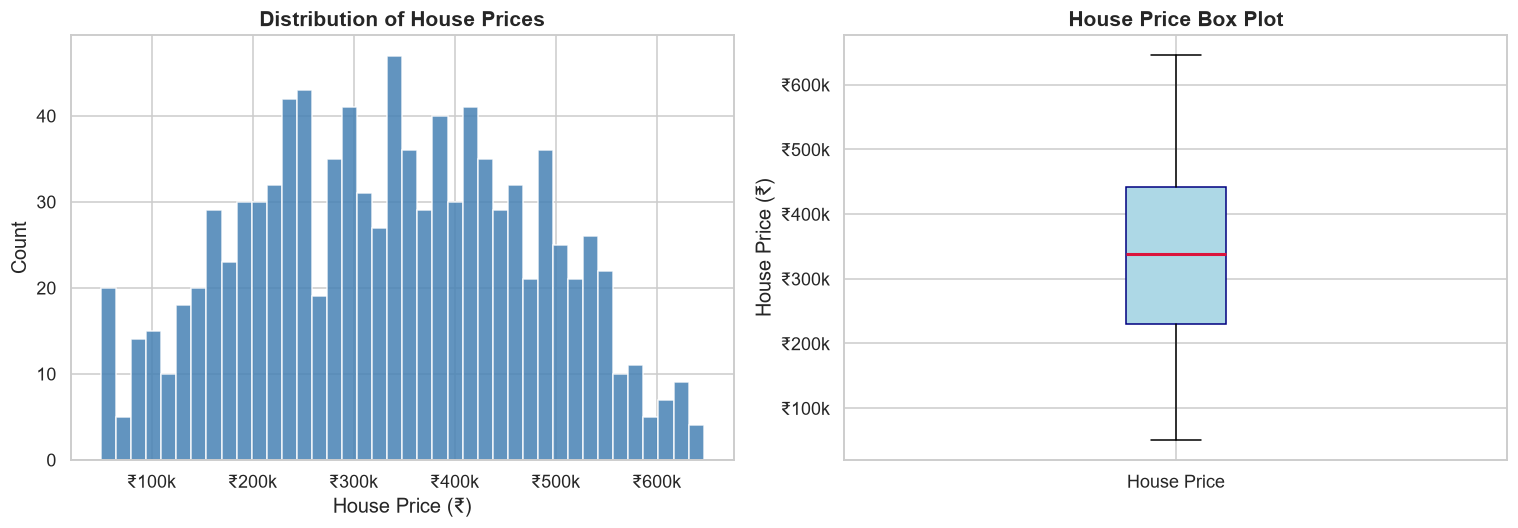

Mean price   : ₹335,642.58
Median price : ₹337,716.95
Std dev      : ₹138,286.26


In [7]:
# ── Visualisation 1 — House Price Distribution ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['house_price'], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribution of House Prices', fontsize=14, fontweight='bold')
axes[0].set_xlabel('House Price (₹)')
axes[0].set_ylabel('Count')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))

# Box plot
axes[1].boxplot(df['house_price'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='navy'),
                medianprops=dict(color='crimson', linewidth=2))
axes[1].set_title('House Price Box Plot', fontsize=14, fontweight='bold')
axes[1].set_ylabel('House Price (₹)')
axes[1].set_xticklabels(['House Price'])
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))

plt.tight_layout()
plt.show()
print(f'Mean price   : ₹{df["house_price"].mean():,.2f}')
print(f'Median price : ₹{df["house_price"].median():,.2f}')
print(f'Std dev      : ₹{df["house_price"].std():,.2f}')

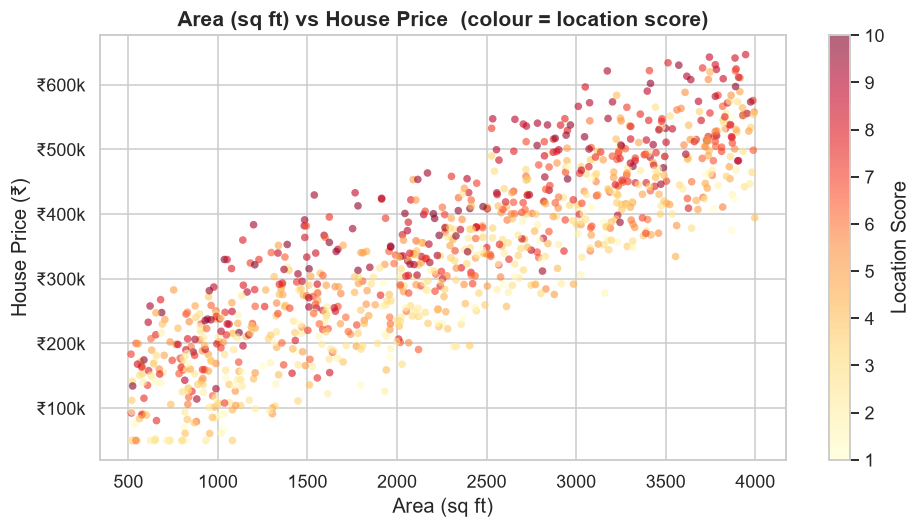

In [8]:
# ── Visualisation 2 — Area vs House Price ─────────────────────────────────────
plt.figure(figsize=(9, 5))
sc = plt.scatter(df['area_sqft'], df['house_price'],
                 c=df['location_score'], cmap='YlOrRd',
                 alpha=0.6, edgecolors='none', s=25)
plt.colorbar(sc, label='Location Score')
plt.title('Area (sq ft) vs House Price  (colour = location score)', fontsize=14, fontweight='bold')
plt.xlabel('Area (sq ft)')
plt.ylabel('House Price (₹)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

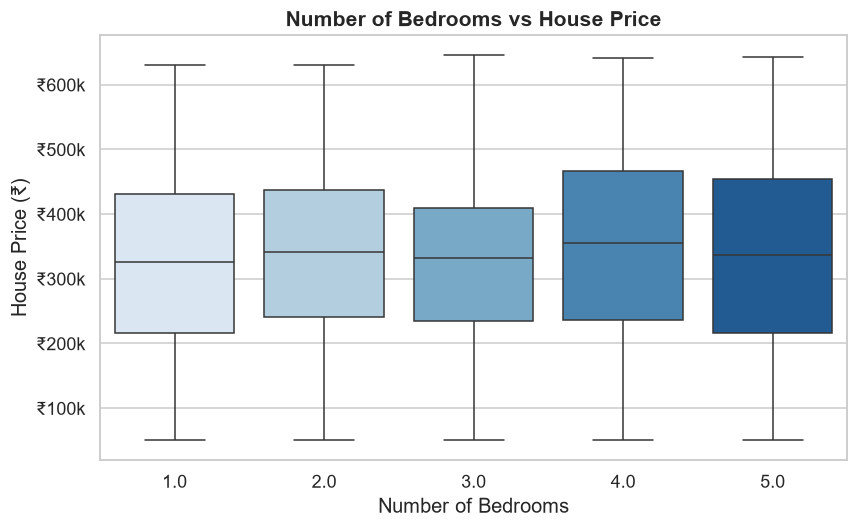

In [9]:
# ── Visualisation 3 — Bedrooms vs House Price ─────────────────────────────────
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='bedrooms', y='house_price', palette='Blues')
plt.title('Number of Bedrooms vs House Price', fontsize=14, fontweight='bold')
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Price (₹)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

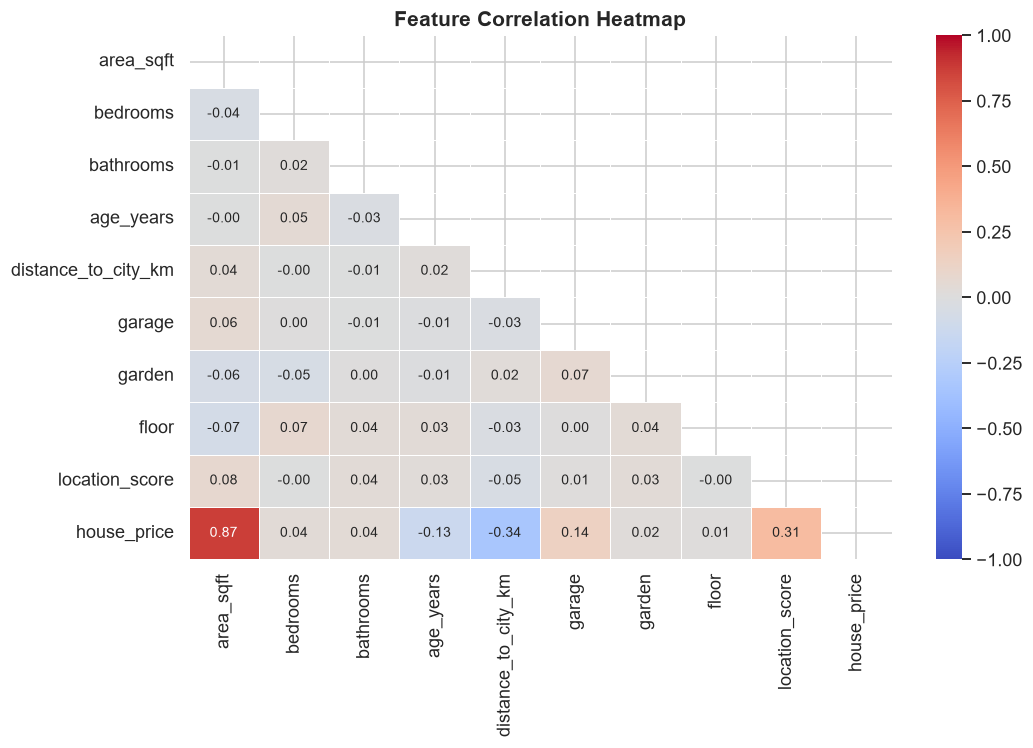

In [10]:
# ── Visualisation 4 — Correlation Heatmap ────────────────────────────────────
plt.figure(figsize=(10, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5,
            annot_kws={'size': 9}, vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

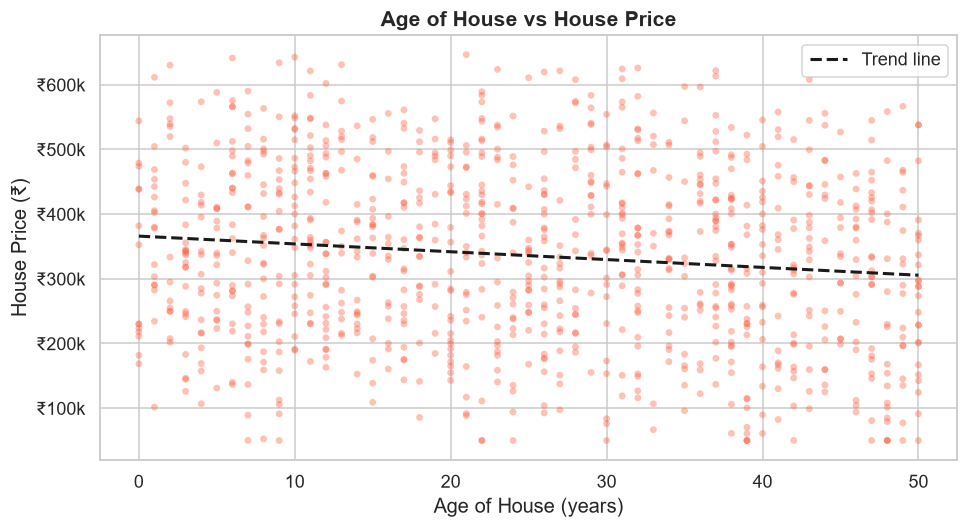

In [11]:
# ── Visualisation 5 — Age vs House Price ─────────────────────────────────────
plt.figure(figsize=(9, 5))
plt.scatter(df['age_years'], df['house_price'],
            alpha=0.4, color='tomato', edgecolors='none', s=20)
# Trend line
z = np.polyfit(df['age_years'], df['house_price'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['age_years'].min(), df['age_years'].max(), 100)
plt.plot(x_line, p(x_line), 'k--', linewidth=2, label='Trend line')
plt.title('Age of House vs House Price', fontsize=14, fontweight='bold')
plt.xlabel('Age of House (years)')
plt.ylabel('House Price (₹)')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

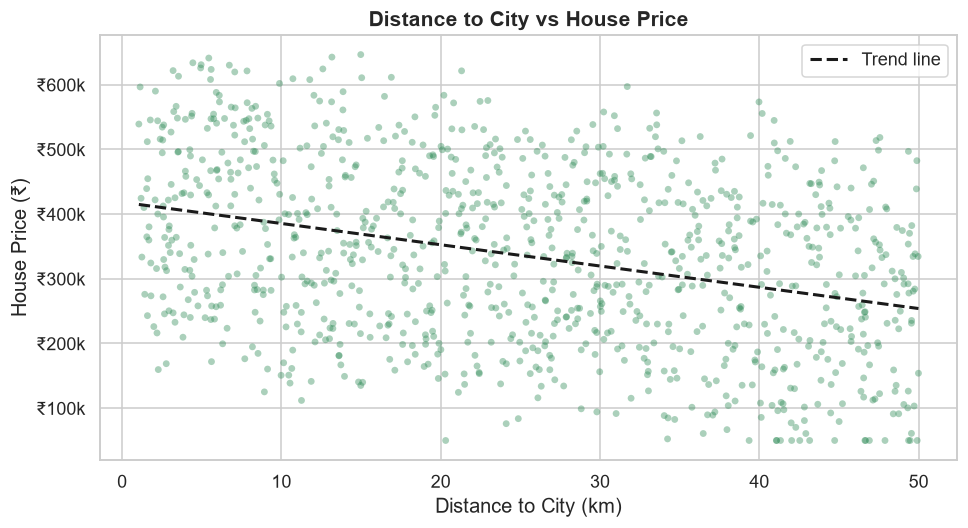

In [12]:
# ── Visualisation 6 — Distance to City vs House Price ────────────────────────
plt.figure(figsize=(9, 5))
plt.scatter(df['distance_to_city_km'], df['house_price'],
            alpha=0.4, color='seagreen', edgecolors='none', s=20)
z = np.polyfit(df['distance_to_city_km'], df['house_price'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['distance_to_city_km'].min(), df['distance_to_city_km'].max(), 100)
plt.plot(x_line, p(x_line), 'k--', linewidth=2, label='Trend line')
plt.title('Distance to City vs House Price', fontsize=14, fontweight='bold')
plt.xlabel('Distance to City (km)')
plt.ylabel('House Price (₹)')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

---
## Section 6 — Data Preprocessing

### Why do we preprocess?

- **Feature/target split** — The model needs to know which column to predict (`house_price`) and which columns to use as inputs.
- **Train-test split** — We hold out 20% of the data so we can evaluate the model on **unseen** examples.
- **Feature scaling (StandardScaler)** — Algorithms like Ridge, Lasso, and linear models are sensitive to feature magnitudes. Scaling transforms every feature to have **zero mean and unit variance**.

> Important: The scaler is fitted **only on the training set** and then applied to both train and test sets. Fitting on the test set would cause *data leakage*.

In [13]:
# ── Feature / target split ────────────────────────────────────────────────────
FEATURES = [
    'area_sqft', 'bedrooms', 'bathrooms', 'age_years',
    'distance_to_city_km', 'garage', 'garden', 'floor', 'location_score'
]
TARGET = 'house_price'

X = df[FEATURES]
y = df[TARGET]

print(f'Features shape : {X.shape}')
print(f'Target shape   : {y.shape}')

# ── Train / test split (80 / 20) ──────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f'\nTraining set   : {X_train.shape[0]} rows')
print(f'Test set       : {X_test.shape[0]} rows')

# ── Feature scaling ───────────────────────────────────────────────────────────
scaler  = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform on train
X_test_scaled  = scaler.transform(X_test)         # transform only on test

print('\nPreprocessing complete!')
print(f'Scaled X_train: mean ~ {X_train_scaled.mean():.4f}, std ~ {X_train_scaled.std():.4f}')

Features shape : (1000, 9)
Target shape   : (1000,)

Training set   : 800 rows
Test set       : 200 rows

Preprocessing complete!
Scaled X_train: mean ~ 0.0000, std ~ 1.0000


---
## Section 7 — Train Multiple Regression Models

We train **five** regression models and evaluate each using four metrics:

| Metric | What it measures | Lower/Higher is better? |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average absolute difference between actual and predicted | Lower |
| **MSE** (Mean Squared Error) | Average squared difference (penalises large errors more) | Lower |
| **RMSE** (Root Mean Squared Error) | Square root of MSE — in the same units as the target | Lower |
| **R2** (R-squared) | Proportion of variance explained (1 = perfect, 0 = no better than mean) | Higher |

In [ ]:
# ── Helper — evaluate a model ─────────────────────────────────────────────────
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """Train model, predict on test set, and return a dict of metrics."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    mae  = mean_absolute_error(y_te, y_pred)
    mse  = mean_squared_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_te, y_pred)
    return {
        'Model' : name,
        'MAE'   : mae,
        'MSE'   : mse,
        'RMSE'  : rmse,
        'R2'    : r2,
    }


# ── Define models ─────────────────────────────────────────────────────────────
models = [
    ('Linear Regression',  LinearRegression()),
    ('Ridge Regression',   Ridge(alpha=1.0, random_state=42)),
    ('Lasso Regression',   Lasso(alpha=100, random_state=42, max_iter=10_000)),
    ('Random Forest',      RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ('Gradient Boosting',  GradientBoostingRegressor(n_estimators=200, random_state=42)),
]

# ── Train & evaluate ──────────────────────────────────────────────────────────
results        = []
scaled_models  = {'Linear Regression', 'Ridge Regression', 'Lasso Regression'}
trained_models = {}   # store fitted models for later use

for name, model in models:
    if name in scaled_models:
        metrics = evaluate_model(name, model, X_train_scaled, y_train, X_test_scaled, y_test)
    else:
        metrics = evaluate_model(name, model, X_train, y_train, X_test, y_test)

    results.append(metrics)
    trained_models[name] = model
    print(f'  {name:25s} | R2={metrics["R2"]:.4f} | RMSE=₹{metrics["RMSE"]:,.0f}')

print('\nAll models trained!')

  Linear Regression         | R2=0.9884 | RMSE=₹15,082
  Ridge Regression          | R2=0.9884 | RMSE=₹15,063
  Lasso Regression          | R2=0.9884 | RMSE=₹15,083
  Random Forest             | R2=0.9477 | RMSE=₹31,985
  Gradient Boosting         | R2=0.9754 | RMSE=₹21,924

All models trained!


---
## Section 8 — Model Comparison

We compare all five models side-by-side.

**How to read the metrics:**
- A high **R2** (close to 1.0) means the model explains most of the variation in prices.
- A low **RMSE** / **MAE** means the model's predictions are close to actual prices on average.
- Tree-based models (Random Forest, Gradient Boosting) often outperform linear models on non-linear data.

In [15]:
# ── Results table ─────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('R2', ascending=False).reset_index(drop=True)

display(
    results_df.style
    .format({'MAE': '₹{:,.2f}', 'MSE': '₹{:,.2f}', 'RMSE': '₹{:,.2f}', 'R2': '{:.4f}'})
    .background_gradient(subset=['R2'], cmap='Greens')
    .background_gradient(subset=['RMSE'], cmap='Reds_r')
    .set_caption('Regression Model Comparison')
)

,Model,MAE,MSE,RMSE,R2
0,Ridge Regression,"₹11,442.37","₹226,901,398.98","₹15,063.25",0.9884
1,Linear Regression,"₹11,449.17","₹227,468,345.91","₹15,082.05",0.9884
2,Lasso Regression,"₹11,465.54","₹227,483,604.11","₹15,082.56",0.9884
3,Gradient Boosting,"₹17,618.25","₹480,678,507.91","₹21,924.38",0.9754
4,Random Forest,"₹26,003.25","₹1,023,020,783.98","₹31,984.70",0.9477


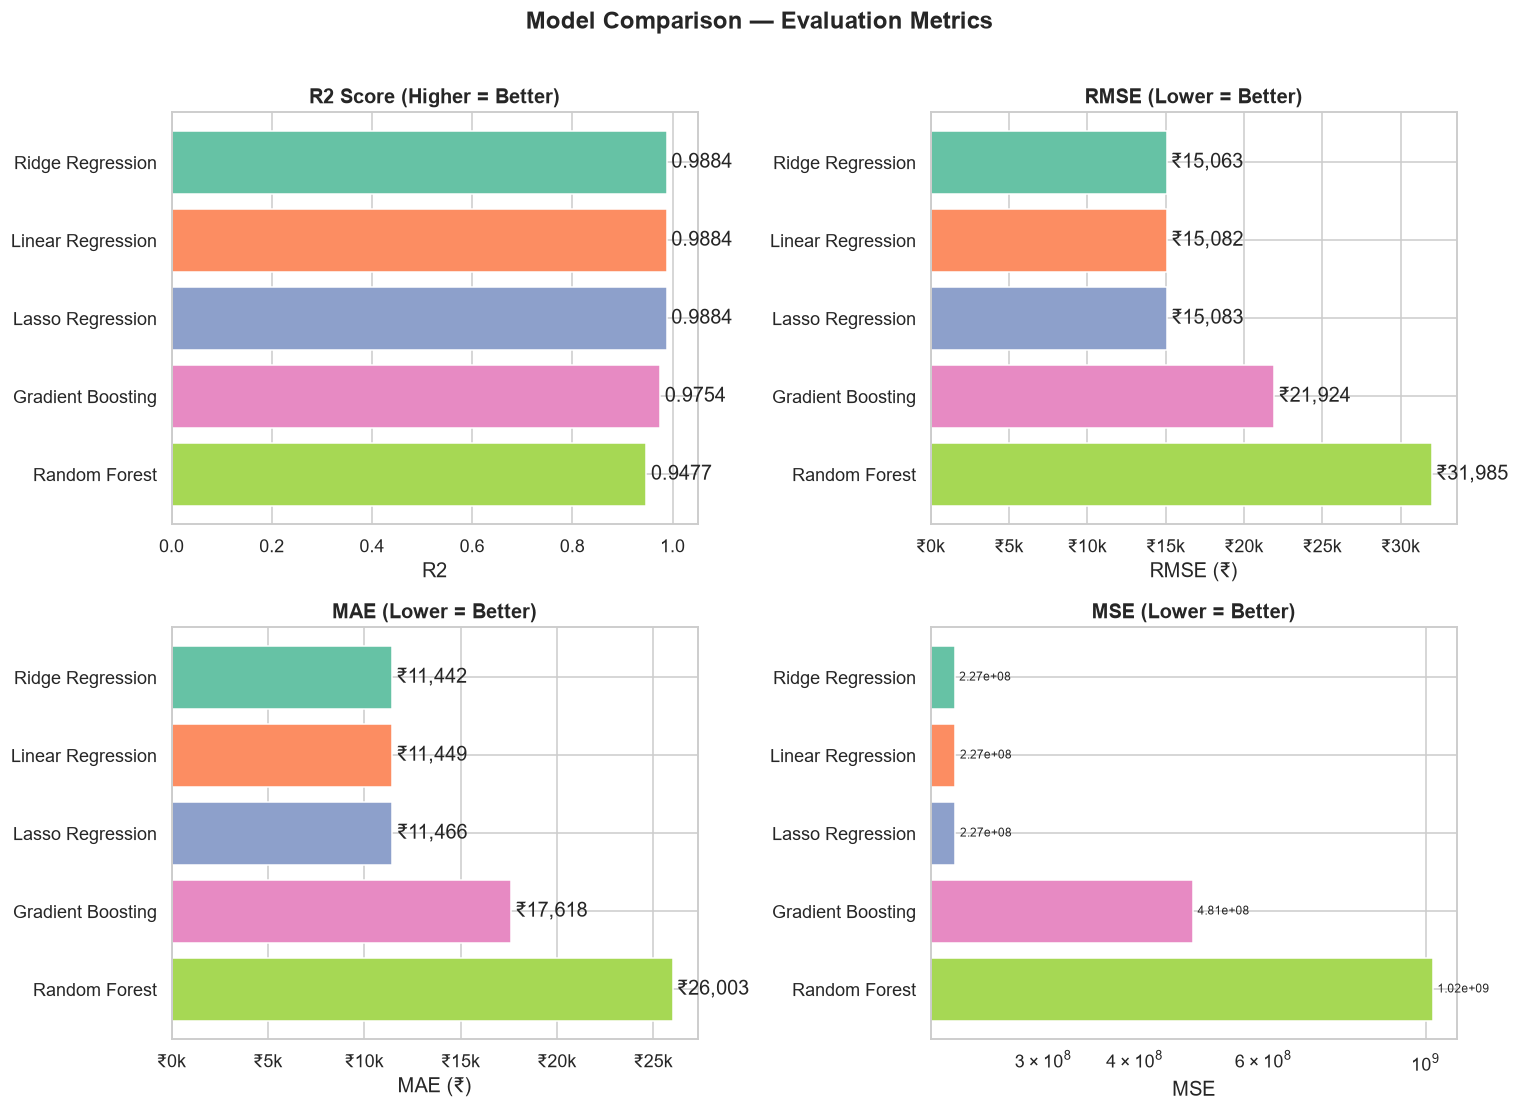

In [16]:
# ── Bar-chart comparison ──────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Model Comparison — Evaluation Metrics', fontsize=16, fontweight='bold', y=1.01)

model_names = results_df['Model']
colors = sns.color_palette('Set2', len(results_df))

# R2
bars = axes[0, 0].barh(model_names, results_df['R2'], color=colors)
axes[0, 0].set_title('R2 Score (Higher = Better)', fontweight='bold')
axes[0, 0].set_xlabel('R2')
axes[0, 0].bar_label(bars, fmt='%.4f', padding=3)
axes[0, 0].set_xlim(0, 1.05)

# RMSE
bars = axes[0, 1].barh(model_names, results_df['RMSE'], color=colors)
axes[0, 1].set_title('RMSE (Lower = Better)', fontweight='bold')
axes[0, 1].set_xlabel('RMSE (₹)')
axes[0, 1].bar_label(bars, fmt='₹{:,.0f}', padding=3)
axes[0, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))

# MAE
bars = axes[1, 0].barh(model_names, results_df['MAE'], color=colors)
axes[1, 0].set_title('MAE (Lower = Better)', fontweight='bold')
axes[1, 0].set_xlabel('MAE (₹)')
axes[1, 0].bar_label(bars, fmt='₹{:,.0f}', padding=3)
axes[1, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))

# MSE (log scale)
bars = axes[1, 1].barh(model_names, results_df['MSE'], color=colors)
axes[1, 1].set_title('MSE (Lower = Better)', fontweight='bold')
axes[1, 1].set_xlabel('MSE')
axes[1, 1].set_xscale('log')
axes[1, 1].bar_label(bars, fmt='%.2e', padding=3, fontsize=8)

for ax in axes.flat:
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

---
## Section 9 — Actual vs Predicted Prices

We select the **best-performing model** (highest R2) and visualise its predictions.

**How to read the plot:**
- Each point represents one house in the test set.
- The **dashed diagonal line** (y = x) is the 'perfect prediction' line.
- Points **close to the diagonal** = good predictions.
- Points **far from the diagonal** = large prediction errors.

Best model : Ridge Regression  (R2=0.9884)


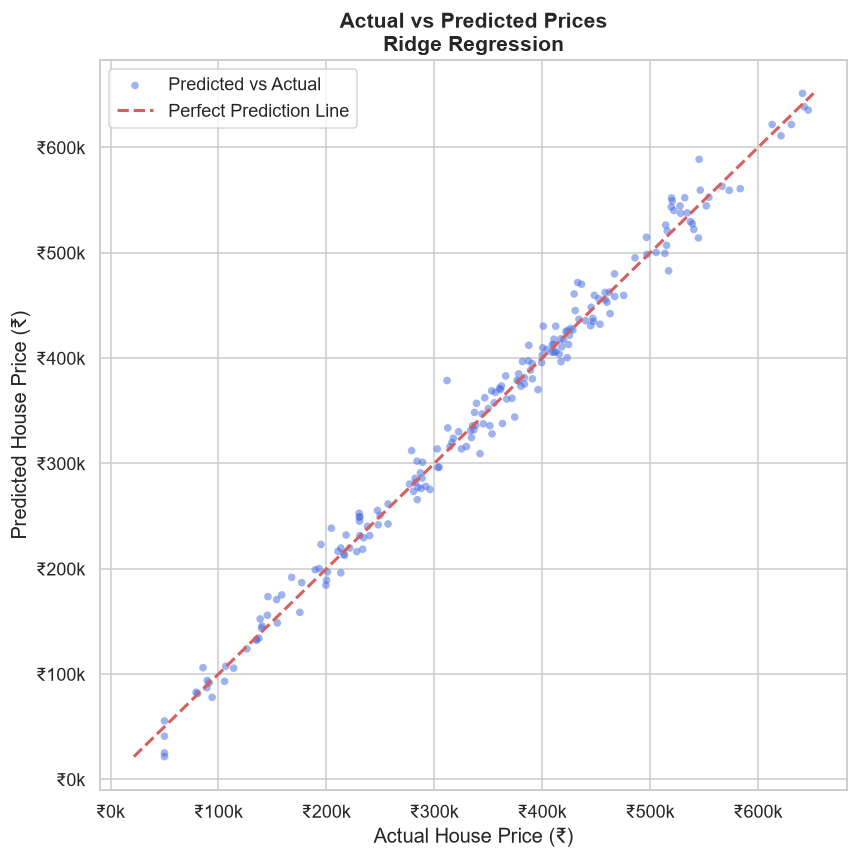

R2   = 0.9884
RMSE = ₹15,063.25
MAE  = ₹11,442.37


In [17]:
# ── Select best model (highest R2) ───────────────────────────────────────────
best_row        = results_df.iloc[0]
best_model_name = best_row['Model']
best_model      = trained_models[best_model_name]
print(f'Best model : {best_model_name}  (R2={best_row["R2"]:.4f})')

# Generate predictions
if best_model_name in {'Linear Regression', 'Ridge Regression', 'Lasso Regression'}:
    y_pred_best = best_model.predict(X_test_scaled)
else:
    y_pred_best = best_model.predict(X_test)

# ── Actual vs Predicted scatter plot ──────────────────────────────────────────
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_best, alpha=0.5, s=25, color='royalblue',
            edgecolors='none', label='Predicted vs Actual')

# Perfect-prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
plt.plot([min_val, max_val], [min_val, max_val],
         'r--', linewidth=2, label='Perfect Prediction Line')

plt.title(f'Actual vs Predicted Prices\n{best_model_name}', fontsize=14, fontweight='bold')
plt.xlabel('Actual House Price (₹)')
plt.ylabel('Predicted House Price (₹)')
plt.legend()
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₹{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

print(f'R2   = {r2_score(y_test, y_pred_best):.4f}')
print(f'RMSE = ₹{np.sqrt(mean_squared_error(y_test, y_pred_best)):,.2f}')
print(f'MAE  = ₹{mean_absolute_error(y_test, y_pred_best):,.2f}')

---
## Section 10 — Feature Importance

**Feature importance** tells us which input features the model relied on most.

- For **tree-based models** (Random Forest, Gradient Boosting): computed by measuring how much each feature reduces prediction error across all splits.
- For **Linear Regression**: the absolute value of coefficients (after scaling) shows relative contributions.

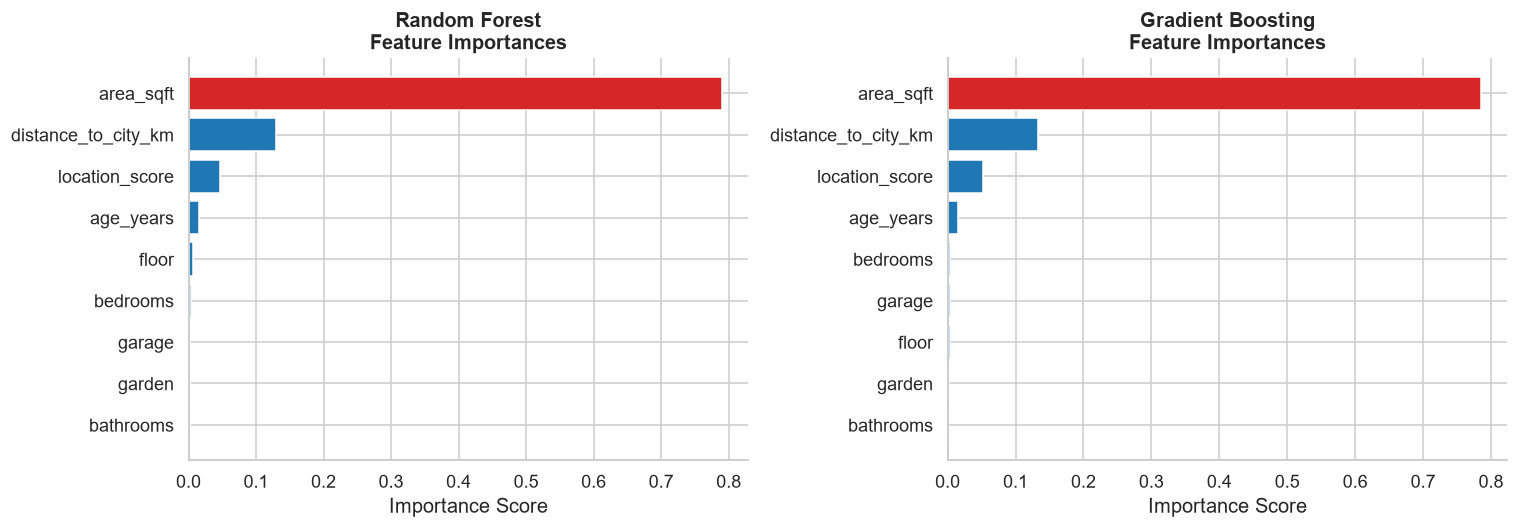

In [18]:
# ── Feature importance for tree-based models ──────────────────────────────────
tree_models = {
    'Random Forest'     : trained_models['Random Forest'],
    'Gradient Boosting' : trained_models['Gradient Boosting'],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (mname, model) in zip(axes, tree_models.items()):
    importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    colors_imp  = ['#d62728' if v == importances.max() else '#1f77b4' for v in importances]
    ax.barh(importances.index, importances.values, color=colors_imp, edgecolor='white')
    ax.set_title(f'{mname}\nFeature Importances', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance Score')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

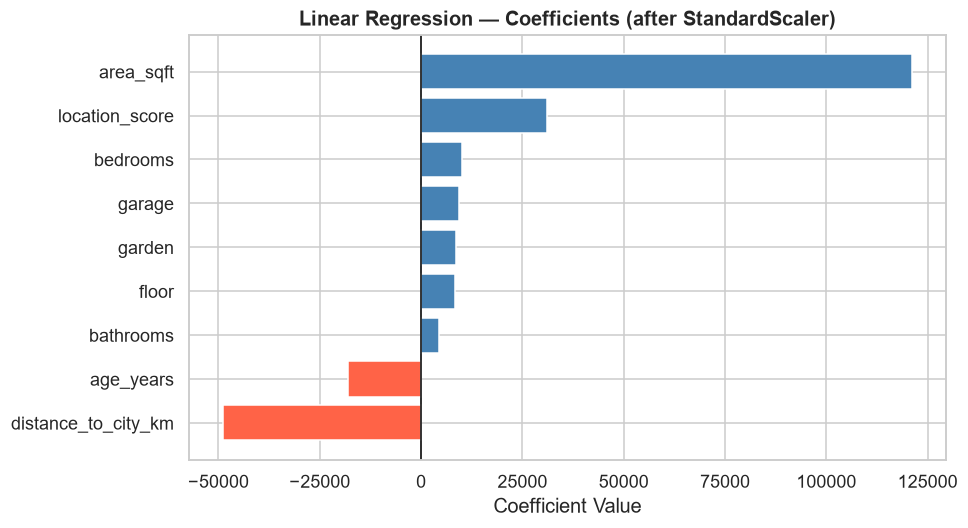

Linear Regression Intercept: ₹333,133.37

Coefficients:


,Feature,Coefficient
4,distance_to_city_km,"₹-48,894.67"
3,age_years,"₹-18,034.47"
2,bathrooms,"₹4,421.57"
7,floor,"₹8,379.02"
6,garden,"₹8,700.40"
5,garage,"₹9,439.84"
1,bedrooms,"₹9,992.59"
8,location_score,"₹31,176.97"
0,area_sqft,"₹121,134.94"


In [19]:
# ── Linear Regression coefficients ────────────────────────────────────────────
lr_model  = trained_models['Linear Regression']
coef_df   = pd.DataFrame({
    'Feature'     : FEATURES,
    'Coefficient' : lr_model.coef_
}).sort_values('Coefficient')

plt.figure(figsize=(9, 5))
colors_lr = ['tomato' if c < 0 else 'steelblue' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_lr, edgecolor='white')
plt.axvline(0, color='black', linewidth=1)
plt.title('Linear Regression — Coefficients (after StandardScaler)', fontsize=13, fontweight='bold')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

print('Linear Regression Intercept:', f'₹{lr_model.intercept_:,.2f}')
print('\nCoefficients:')
display(coef_df.style.format({'Coefficient': '₹{:,.2f}'}))

---
## Section 11 — Make a Sample Prediction

Let's demonstrate how to use the trained model to predict the price of a **new, unseen house**.

In [20]:
# ── Define a new house ────────────────────────────────────────────────────────
new_house = {
    'area_sqft'           : 2500,   # 2,500 sq ft
    'bedrooms'            : 4,      # 4 bedrooms
    'bathrooms'           : 2,      # 2 bathrooms
    'age_years'           : 10,     # 10 years old
    'distance_to_city_km' : 15.0,   # 15 km from city centre
    'garage'              : 1,      # has garage
    'garden'              : 1,      # has garden
    'floor'               : 3,      # floor 3
    'location_score'      : 7.5,    # good location
}

new_df = pd.DataFrame([new_house])[FEATURES]

# ── Predict using the best model ──────────────────────────────────────────────
if best_model_name in {'Linear Regression', 'Ridge Regression', 'Lasso Regression'}:
    new_df_scaled   = scaler.transform(new_df)
    predicted_price = best_model.predict(new_df_scaled)[0]
else:
    predicted_price = best_model.predict(new_df)[0]

print('=' * 50)
print('  SAMPLE PREDICTION')
print('=' * 50)
for k, v in new_house.items():
    print(f'  {k:<25}: {v}')
print('-' * 50)
print(f'  Model used             : {best_model_name}')
print(f'  Predicted Price        : ₹{predicted_price:,.2f}')
print('=' * 50)

  SAMPLE PREDICTION
  area_sqft                : 2500
  bedrooms                 : 4
  bathrooms                : 2
  age_years                : 10
  distance_to_city_km      : 15.0
  garage                   : 1
  garden                   : 1
  floor                    : 3
  location_score           : 7.5
--------------------------------------------------
  Model used             : Ridge Regression
  Predicted Price        : ₹463,453.95


---
## Section 12 — Save the Model

We persist both the trained model and the scaler so they can be reloaded later **without re-training**.

In [ ]:
# ── Save model & scaler ───────────────────────────────────────────────────────
joblib.dump(best_model, 'house_price_model.pkl')
joblib.dump(scaler,     'house_price_scaler.pkl')

print(f'Model saved  : house_price_model.pkl  ({best_model_name})')
print(f'Scaler saved : house_price_scaler.pkl')

---
## Section 13 — Load and Test the Saved Model

This section shows how to reload the model from disk and use it — exactly as you would in a real application.

In [21]:
# ── Reload model & scaler ────────────────────────────────────────────────────
loaded_model  = joblib.load('house_price_model.pkl')
loaded_scaler = joblib.load('house_price_scaler.pkl')

print('Model and scaler loaded from disk!')
print(f'Model type : {type(loaded_model).__name__}')

# ── Run inference with loaded model ───────────────────────────────────────────
sample_house = pd.DataFrame([{
    'area_sqft'           : 1800,
    'bedrooms'            : 3,
    'bathrooms'           : 2,
    'age_years'           : 20,
    'distance_to_city_km' : 10.0,
    'garage'              : 0,
    'garden'              : 1,
    'floor'               : 2,
    'location_score'      : 6.0,
}])[FEATURES]

# Apply scaler only if the loaded model is linear-based
loaded_model_name = type(loaded_model).__name__
if loaded_model_name in {'LinearRegression', 'Ridge', 'Lasso'}:
    sample_scaled = loaded_scaler.transform(sample_house)
    price = loaded_model.predict(sample_scaled)[0]
else:
    price = loaded_model.predict(sample_house)[0]

print(f'\nSample house prediction (loaded model):')
print(f'  Predicted Price : ₹{price:,.2f}')

Model and scaler loaded from disk!
Model type : Ridge

Sample house prediction (loaded model):
  Predicted Price : ₹338,432.76


---
## Section 14 — Conclusion

### What was done in this project

1. **Generated** a synthetic dataset of 1,000 houses with 9 meaningful features.
2. **Explored** the data through summary statistics and six visualisations.
3. **Pre-processed** the data with a reproducible train/test split and StandardScaler.
4. **Trained** five regression models: Linear Regression, Ridge, Lasso, Random Forest, and Gradient Boosting.
5. **Evaluated** each model on MAE, MSE, RMSE, and R2.
6. **Identified** the best model and visualised its predictions.
7. **Explained** feature importance to understand what drives house prices.
8. **Demonstrated** how to make a new prediction and save/load the model.

---

### What the metrics mean

| Metric | Interpretation |
|---|---|
| **R2 close to 1.0** | Model explains almost all variation in prices |
| **Low RMSE** | Predictions are, on average, close to actual prices |
| **Low MAE** | Robust measure of typical error magnitude |

---

### How the model can be improved

- **Hyperparameter tuning** — Use `GridSearchCV` or `RandomizedSearchCV` to find optimal settings.
- **Feature engineering** — Create interaction terms (e.g., `area x location_score`).
- **Cross-validation** — Use k-fold CV for a more robust evaluation.
- **More data** — Collect real-world data with additional features.
- **Other algorithms** — Try XGBoost, LightGBM, or a neural network.

---

### Real-world applications

- Real-estate websites (Zillow, Rightmove) to provide instant price estimates.
- Banks and lenders for property valuation during mortgage assessments.
- Property investors to identify under- or over-valued homes.
- Urban planners to model how infrastructure changes affect property values.

---

### Limitations of using a synthetic dataset

- The price formula is **linear by design** — real-world prices are influenced by hundreds of non-linear factors.
- The dataset contains **no outliers or complex noise patterns** that would appear in real data.
- A model trained on this data **cannot be deployed** for actual property valuations without genuine, curated data.
- The dataset does not capture **temporal dynamics** (market trends, economic cycles).